# 04 — Avaliação do potencial de impacto na locomoção — V2

Esta versão mantém a regra original (**V1**) e adiciona uma nova variável espacial:

- classe do objeto;
- posição horizontal;
- ocupação da imagem;
- **posição vertical da bounding box**.

O objetivo é reduzir falsos alertas para objetos visualmente elevados, como uma planta sobre uma mesa.

## Fluxo

```text
Imagem
   ↓
YOLOv8n
   ↓
objeto + bounding box + confiança
   ↓
classe
   +
posição horizontal
   +
ocupação da imagem
   +
posição vertical
   ↓
comparação V1 x V2
   ↓
BAIXO / MÉDIO / ALTO
```

> A posição vertical é uma heurística visual. Ela não representa distância real e não garante que o objeto esteja no chão.

## 1. Pré-requisitos

O modelo treinado deve estar em:

```text
tcc_visao_computacional/
└── models/
    └── yolov8n_baseline/
        └── best.pt
```

E o dataset processado em:

```text
data/processed/homeobjects_yolo/
```

## 2. Importações e localização do projeto

In [18]:
from pathlib import Path
import random
import sys

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image, ImageDraw


def localizar_raiz_projeto() -> Path:
    atual = Path.cwd().resolve()

    for candidata in [atual, *atual.parents]:
        if (
            (candidata / "requirements.txt").exists()
            and (candidata / "src").exists()
        ):
            return candidata

    raise FileNotFoundError(
        "Não foi possível localizar a raiz do projeto."
    )


RAIZ_PROJETO = localizar_raiz_projeto()

if str(RAIZ_PROJETO) not in sys.path:
    sys.path.insert(0, str(RAIZ_PROJETO))

print("Raiz do projeto:", RAIZ_PROJETO)

Raiz do projeto: C:\Users\diego\OneDrive\Documentos_One_Drive\TCC\tcc_visao_computacional


## 3. Importar Ultralytics

In [19]:
try:
    from ultralytics import YOLO
except ImportError:
    import subprocess

    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "ultralytics"]
    )

    from ultralytics import YOLO

print("Ultralytics importado com sucesso.")

Ultralytics importado com sucesso.


## 4. Caminhos do projeto

In [20]:
CAMINHO_MODELO = (
    RAIZ_PROJETO
    / "models"
    / "yolov8n_baseline"
    / "best.pt"
)

PASTA_TEST = (
    RAIZ_PROJETO
    / "data"
    / "processed"
    / "homeobjects_yolo"
    / "images"
    / "test"
)

PASTA_RESULTADOS = (
    RAIZ_PROJETO
    / "reports"
    / "predictions"
    / "risco_v2"
)

PASTA_TABELAS = (
    RAIZ_PROJETO
    / "reports"
    / "tables"
)

PASTA_RESULTADOS.mkdir(parents=True, exist_ok=True)
PASTA_TABELAS.mkdir(parents=True, exist_ok=True)

if not CAMINHO_MODELO.exists():
    raise FileNotFoundError(
        f"best.pt não encontrado em:\n{CAMINHO_MODELO}"
    )

if not PASTA_TEST.exists():
    raise FileNotFoundError(
        f"Pasta de teste não encontrada em:\n{PASTA_TEST}"
    )

print("Modelo:", CAMINHO_MODELO)
print("Imagens de teste:", PASTA_TEST)
print("Resultados:", PASTA_RESULTADOS)

Modelo: C:\Users\diego\OneDrive\Documentos_One_Drive\TCC\tcc_visao_computacional\models\yolov8n_baseline\best.pt
Imagens de teste: C:\Users\diego\OneDrive\Documentos_One_Drive\TCC\tcc_visao_computacional\data\processed\homeobjects_yolo\images\test
Resultados: C:\Users\diego\OneDrive\Documentos_One_Drive\TCC\tcc_visao_computacional\reports\predictions\risco_v2


# 5. Relevância das classes

As 12 classes continuam sendo detectadas pelo YOLO.

Para avaliação de locomoção:

### Possíveis obstáculos físicos
- bed
- sofa
- chair
- table
- wardrobe
- potted plant

### Contextuais
- lamp
- door

### Ignoradas para risco
- tv
- laptop
- window
- photo frame

In [21]:
PESO_OBJETO = {
    "bed": 3,
    "sofa": 3,
    "chair": 3,
    "table": 3,
    "wardrobe": 3,
    "potted plant": 2,
}

CLASSES_CONTEXTUAIS = {
    "lamp",
    "door",
}

CLASSES_IGNORADAS = {
    "tv",
    "laptop",
    "window",
    "photo frame",
}

print("Possíveis obstáculos:", sorted(PESO_OBJETO))
print("Contextuais:", sorted(CLASSES_CONTEXTUAIS))
print("Ignoradas:", sorted(CLASSES_IGNORADAS))

Possíveis obstáculos: ['bed', 'chair', 'potted plant', 'sofa', 'table', 'wardrobe']
Contextuais: ['door', 'lamp']
Ignoradas: ['laptop', 'photo frame', 'tv', 'window']


# 6. Regras espaciais

## Posição horizontal

```text
┌────────────┬────────────┬────────────┐
│  esquerda  │   centro   │   direita  │
└────────────┴────────────┴────────────┘
```

## Ocupação da imagem

- pequeno: menos de 5%;
- médio: de 5% até menos de 20%;
- grande: 20% ou mais.

## Posição vertical

A posição vertical utiliza o ponto inferior da bounding box (`y2`):

- superior: `y2 < 60%` da altura;
- intermediária: `60% <= y2 < 80%`;
- inferior: `y2 >= 80%`.

Na V2 a posição vertical apenas **reduz** risco quando o objeto termina muito acima da parte inferior da imagem.

In [22]:
LIMITE_ESQUERDA = 1 / 3
LIMITE_DIREITA = 2 / 3

LIMITE_AREA_MEDIA = 0.05
LIMITE_AREA_GRANDE = 0.20

LIMITE_VERTICAL_SUPERIOR = 0.60
LIMITE_VERTICAL_INFERIOR = 0.80

PESO_POSICAO = {
    "esquerda": 1,
    "centro": 3,
    "direita": 1,
}

PESO_TAMANHO = {
    "pequeno": 1,
    "medio": 2,
    "grande": 3,
}

AJUSTE_VERTICAL = {
    "superior": -2,
    "intermediaria": -1,
    "inferior": 0,
}

## 7. Funções de classificação

In [23]:
def classificar_posicao(
    centro_x: float,
    largura_imagem: int,
) -> str:
    centro_normalizado = centro_x / largura_imagem

    if centro_normalizado < LIMITE_ESQUERDA:
        return "esquerda"

    if centro_normalizado < LIMITE_DIREITA:
        return "centro"

    return "direita"


def classificar_tamanho(
    area_box: float,
    area_imagem: float,
):
    proporcao = area_box / area_imagem

    if proporcao < LIMITE_AREA_MEDIA:
        return "pequeno", proporcao

    if proporcao < LIMITE_AREA_GRANDE:
        return "medio", proporcao

    return "grande", proporcao


def classificar_posicao_vertical(
    y2: float,
    altura_imagem: int,
):
    proporcao_vertical = y2 / altura_imagem

    if proporcao_vertical < LIMITE_VERTICAL_SUPERIOR:
        return "superior", proporcao_vertical

    if proporcao_vertical < LIMITE_VERTICAL_INFERIOR:
        return "intermediaria", proporcao_vertical

    return "inferior", proporcao_vertical

## 8. Regra V1

A regra original utiliza:

```text
tipo do objeto
+ posição horizontal
+ tamanho
```

In [24]:
def classificar_risco_v1(
    classe: str,
    posicao: str,
    tamanho: str,
):
    if classe in CLASSES_IGNORADAS:
        return {
            "pontuacao": 0,
            "nivel_risco": "ignorado",
            "motivo": "classe sem relevância direta para locomoção",
        }

    if classe in CLASSES_CONTEXTUAIS:
        return {
            "pontuacao": None,
            "nivel_risco": "contextual",
            "motivo": "classe exige informação adicional de contexto",
        }

    if classe not in PESO_OBJETO:
        return {
            "pontuacao": None,
            "nivel_risco": "nao_mapeado",
            "motivo": "classe não configurada",
        }

    pontuacao = (
        PESO_OBJETO[classe]
        + PESO_POSICAO[posicao]
        + PESO_TAMANHO[tamanho]
    )

    if pontuacao <= 4:
        nivel = "baixo"
    elif pontuacao <= 6:
        nivel = "medio"
    else:
        nivel = "alto"

    return {
        "pontuacao": pontuacao,
        "nivel_risco": nivel,
        "motivo": (
            f"{classe} + posição {posicao} + tamanho {tamanho}"
        ),
    }

## 9. Regra V2

A V2 parte da pontuação da V1 e aplica:

```text
região superior       → -2 pontos
região intermediária  → -1 ponto
região inferior       →  0 pontos
```

In [25]:
def classificar_risco_v2(
    classe: str,
    posicao: str,
    tamanho: str,
    posicao_vertical: str,
):
    avaliacao_v1 = classificar_risco_v1(
        classe=classe,
        posicao=posicao,
        tamanho=tamanho,
    )

    if avaliacao_v1["nivel_risco"] in {
        "ignorado",
        "contextual",
        "nao_mapeado",
    }:
        return {
            "pontuacao": avaliacao_v1["pontuacao"],
            "nivel_risco": avaliacao_v1["nivel_risco"],
            "ajuste_vertical": 0,
            "motivo": avaliacao_v1["motivo"],
        }

    ajuste_vertical = AJUSTE_VERTICAL[posicao_vertical]

    pontuacao = max(
        1,
        avaliacao_v1["pontuacao"] + ajuste_vertical,
    )

    if pontuacao <= 4:
        nivel = "baixo"
    elif pontuacao <= 6:
        nivel = "medio"
    else:
        nivel = "alto"

    return {
        "pontuacao": pontuacao,
        "nivel_risco": nivel,
        "ajuste_vertical": ajuste_vertical,
        "motivo": (
            f"{classe} + posição {posicao} "
            f"+ tamanho {tamanho} "
            f"+ região vertical {posicao_vertical}"
        ),
    }

## 10. Carregar o modelo

In [26]:
modelo = YOLO(str(CAMINHO_MODELO))

print("Modelo carregado.")
print("Classes:")
print(modelo.names)

Modelo carregado.
Classes:
{0: 'bed', 1: 'sofa', 2: 'chair', 3: 'table', 4: 'lamp', 5: 'tv', 6: 'laptop', 7: 'wardrobe', 8: 'window', 9: 'door', 10: 'potted plant', 11: 'photo frame'}


# 11. Análise completa de uma imagem

A função abaixo retorna, para cada detecção:

- classe;
- confiança;
- bounding box;
- posição horizontal;
- tamanho;
- posição vertical;
- risco V1;
- risco V2.

In [27]:
def analisar_imagem(
    caminho_imagem,
    confianca_minima=0.25,
):
    caminho_imagem = Path(caminho_imagem)

    imagem = Image.open(caminho_imagem).convert("RGB")
    largura, altura = imagem.size
    area_imagem = largura * altura

    resultados = modelo.predict(
        source=str(caminho_imagem),
        conf=confianca_minima,
        verbose=False,
    )

    resultado = resultados[0]
    registros = []

    if resultado.boxes is None:
        return pd.DataFrame(), imagem

    for box in resultado.boxes:
        classe_id = int(box.cls[0].item())
        classe = modelo.names[classe_id]
        confianca = float(box.conf[0].item())

        x1, y1, x2, y2 = [
            float(valor)
            for valor in box.xyxy[0].tolist()
        ]

        largura_box = x2 - x1
        altura_box = y2 - y1
        area_box = largura_box * altura_box

        centro_x = (x1 + x2) / 2

        posicao = classificar_posicao(
            centro_x=centro_x,
            largura_imagem=largura,
        )

        tamanho, proporcao_area = classificar_tamanho(
            area_box=area_box,
            area_imagem=area_imagem,
        )

        posicao_vertical, proporcao_vertical = (
            classificar_posicao_vertical(
                y2=y2,
                altura_imagem=altura,
            )
        )

        avaliacao_v1 = classificar_risco_v1(
            classe=classe,
            posicao=posicao,
            tamanho=tamanho,
        )

        avaliacao_v2 = classificar_risco_v2(
            classe=classe,
            posicao=posicao,
            tamanho=tamanho,
            posicao_vertical=posicao_vertical,
        )

        registros.append(
            {
                "arquivo": caminho_imagem.name,
                "classe": classe,
                "confianca": confianca,
                "x1": x1,
                "y1": y1,
                "x2": x2,
                "y2": y2,
                "posicao": posicao,
                "ocupacao_imagem": proporcao_area,
                "tamanho": tamanho,
                "posicao_vertical": posicao_vertical,
                "proporcao_vertical": proporcao_vertical,
                "pontuacao_v1": avaliacao_v1["pontuacao"],
                "nivel_risco_v1": avaliacao_v1["nivel_risco"],
                "ajuste_vertical": avaliacao_v2["ajuste_vertical"],
                "pontuacao_v2": avaliacao_v2["pontuacao"],
                "nivel_risco_v2": avaliacao_v2["nivel_risco"],
                "motivo": avaliacao_v2["motivo"],
            }
        )

    return pd.DataFrame(registros), imagem

## 12. Selecionar uma imagem do TEST

In [28]:
EXTENSOES_IMAGEM = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

imagens_test = sorted(
    arquivo
    for arquivo in PASTA_TEST.rglob("*")
    if arquivo.is_file()
    and arquivo.suffix.lower() in EXTENSOES_IMAGEM
)

if not imagens_test:
    raise RuntimeError("Nenhuma imagem encontrada no conjunto TEST.")

random.seed(42)
imagem_teste = random.choice(imagens_test)

print("Imagem selecionada:")
print(imagem_teste)

Imagem selecionada:
C:\Users\diego\OneDrive\Documentos_One_Drive\TCC\tcc_visao_computacional\data\processed\homeobjects_yolo\images\test\living_room_712.jpg


## 13. Executar a avaliação

In [29]:
df_deteccoes, imagem_original = analisar_imagem(
    imagem_teste,
    confianca_minima=0.25,
)

colunas_exibicao = [
    "classe",
    "confianca",
    "posicao",
    "ocupacao_imagem",
    "tamanho",
    "posicao_vertical",
    "proporcao_vertical",
    "pontuacao_v1",
    "nivel_risco_v1",
    "ajuste_vertical",
    "pontuacao_v2",
    "nivel_risco_v2",
]

if df_deteccoes.empty:
    print("Nenhum objeto detectado.")
else:
    display(
        df_deteccoes[colunas_exibicao]
        .sort_values(
            ["nivel_risco_v2", "confianca"],
            ascending=[True, False],
        )
    )

,classe,confianca,posicao,ocupacao_imagem,tamanho,posicao_vertical,proporcao_vertical,pontuacao_v1,nivel_risco_v1,ajuste_vertical,pontuacao_v2,nivel_risco_v2
0,table,0.939651,centro,0.378741,grande,inferior,0.998764,9.0,alto,0,9.0,alto
4,potted plant,0.680065,direita,0.010674,pequeno,superior,0.396625,4.0,baixo,-2,2.0,baixo
7,potted plant,0.297869,direita,0.005274,pequeno,superior,0.399558,4.0,baixo,-2,2.0,baixo
6,lamp,0.308247,centro,0.006218,pequeno,superior,0.217249,NaN,contextual,0,NaN,contextual
8,door,0.266342,esquerda,0.061288,medio,superior,0.580095,NaN,contextual,0,NaN,contextual
2,photo frame,0.811196,centro,0.008900,pequeno,superior,0.406841,0.0,ignorado,0,0.0,ignorado
9,laptop,0.250229,direita,0.029225,pequeno,intermediaria,0.684032,0.0,ignorado,0,0.0,ignorado
1,potted plant,0.891022,centro,0.090275,medio,intermediaria,0.664662,7.0,alto,-1,6.0,medio
3,chair,0.732377,esquerda,0.085972,medio,inferior,0.917378,6.0,medio,0,6.0,medio
5,chair,0.436645,esquerda,0.108749,medio,inferior,1.000000,6.0,medio,0,6.0,medio


# 14. Visualização

A imagem é dividida em:

- três regiões horizontais;
- três regiões verticais.

O texto de cada bounding box mostra a classificação **V2**.

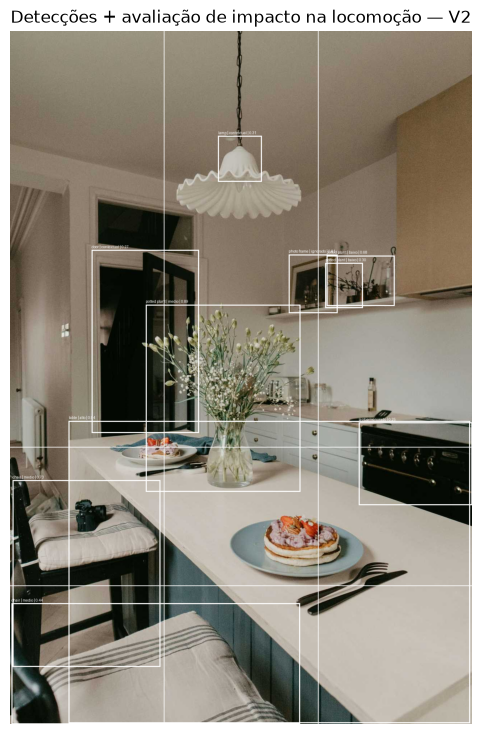

In [30]:
def desenhar_resultados(
    imagem,
    df,
):
    imagem_saida = imagem.copy()
    desenho = ImageDraw.Draw(imagem_saida)

    largura, altura = imagem_saida.size

    x_esquerda = int(largura * LIMITE_ESQUERDA)
    x_direita = int(largura * LIMITE_DIREITA)

    y_superior = int(
        altura * LIMITE_VERTICAL_SUPERIOR
    )

    y_inferior = int(
        altura * LIMITE_VERTICAL_INFERIOR
    )

    desenho.line(
        [(x_esquerda, 0), (x_esquerda, altura)],
        width=2,
    )

    desenho.line(
        [(x_direita, 0), (x_direita, altura)],
        width=2,
    )

    desenho.line(
        [(0, y_superior), (largura, y_superior)],
        width=2,
    )

    desenho.line(
        [(0, y_inferior), (largura, y_inferior)],
        width=2,
    )

    for _, linha in df.iterrows():
        caixa = (
            linha["x1"],
            linha["y1"],
            linha["x2"],
            linha["y2"],
        )

        desenho.rectangle(
            caixa,
            width=3,
        )

        texto = (
            f'{linha["classe"]} | '
            f'{linha["nivel_risco_v2"]} | '
            f'{linha["confianca"]:.2f}'
        )

        desenho.text(
            (linha["x1"], max(linha["y1"] - 15, 0)),
            texto,
        )

    return imagem_saida


imagem_anotada = desenhar_resultados(
    imagem_original,
    df_deteccoes,
)

plt.figure(figsize=(14, 9))
plt.imshow(imagem_anotada)
plt.axis("off")
plt.title("Detecções + avaliação de impacto na locomoção — V2")
plt.show()

## 15. Comparar V1 e V2 na imagem selecionada

In [31]:
if not df_deteccoes.empty:
    comparacao_imagem = df_deteccoes[
        [
            "classe",
            "posicao",
            "tamanho",
            "posicao_vertical",
            "pontuacao_v1",
            "nivel_risco_v1",
            "ajuste_vertical",
            "pontuacao_v2",
            "nivel_risco_v2",
        ]
    ].copy()

    comparacao_imagem["mudou"] = (
        comparacao_imagem["nivel_risco_v1"]
        != comparacao_imagem["nivel_risco_v2"]
    )

    display(comparacao_imagem)

,classe,posicao,tamanho,posicao_vertical,pontuacao_v1,nivel_risco_v1,ajuste_vertical,pontuacao_v2,nivel_risco_v2,mudou
0,table,centro,grande,inferior,9.0,alto,0,9.0,alto,False
1,potted plant,centro,medio,intermediaria,7.0,alto,-1,6.0,medio,True
2,photo frame,centro,pequeno,superior,0.0,ignorado,0,0.0,ignorado,False
3,chair,esquerda,medio,inferior,6.0,medio,0,6.0,medio,False
4,potted plant,direita,pequeno,superior,4.0,baixo,-2,2.0,baixo,False
5,chair,esquerda,medio,inferior,6.0,medio,0,6.0,medio,False
6,lamp,centro,pequeno,superior,NaN,contextual,0,NaN,contextual,False
7,potted plant,direita,pequeno,superior,4.0,baixo,-2,2.0,baixo,False
8,door,esquerda,medio,superior,NaN,contextual,0,NaN,contextual,False
9,laptop,direita,pequeno,intermediaria,0.0,ignorado,0,0.0,ignorado,False


## 16. Mensagens usando a regra V2

In [32]:
def gerar_mensagens(df):
    mensagens = []

    if df.empty:
        return ["Nenhum objeto relevante detectado."]

    riscos = df[
        df["nivel_risco_v2"].isin(["medio", "alto"])
    ].copy()

    ordem = {
        "alto": 0,
        "medio": 1,
    }

    if riscos.empty:
        return ["Nenhum obstáculo relevante identificado."]

    riscos["ordem"] = riscos["nivel_risco_v2"].map(ordem)

    riscos = riscos.sort_values(
        ["ordem", "ocupacao_imagem"],
        ascending=[True, False],
    )

    for _, linha in riscos.iterrows():
        if linha["nivel_risco_v2"] == "alto":
            prefixo = "Cuidado"
        else:
            prefixo = "Atenção"

        mensagens.append(
            f'{prefixo}: {linha["classe"]} '
            f'{linha["posicao"]}.'
        )

    return mensagens


mensagens = gerar_mensagens(df_deteccoes)

for mensagem in mensagens:
    print(mensagem)

Cuidado: table centro.
Atenção: chair esquerda.
Atenção: potted plant centro.
Atenção: chair esquerda.


# 17. Testar 20 imagens do TEST

Agora aplicamos a regra V1 e a V2 sobre a mesma amostra de 20 imagens.

In [33]:
random.seed(42)

quantidade_amostras = min(20, len(imagens_test))

amostras = random.sample(
    imagens_test,
    quantidade_amostras,
)

resultados_amostras = []

for indice, caminho_imagem in enumerate(amostras, start=1):
    print(
        f"[{indice:02d}/{quantidade_amostras}] "
        f"{caminho_imagem.name}"
    )

    df_imagem, _ = analisar_imagem(
        caminho_imagem,
        confianca_minima=0.25,
    )

    if not df_imagem.empty:
        resultados_amostras.append(df_imagem)

if resultados_amostras:
    df_amostras = pd.concat(
        resultados_amostras,
        ignore_index=True,
    )
else:
    df_amostras = pd.DataFrame()

print()
print("Detecções analisadas:", len(df_amostras))

[01/20] living_room_712.jpg
[02/20] living_room_1p (118).jpg
[03/20] living_room_1040.jpg
[04/20] living_room_908.jpg
[05/20] living_room_1p (439).jpg
[06/20] living_room_1p (382).jpg
[07/20] living_room_1p (339).jpg
[08/20] living_room_1p (173).jpg
[09/20] living_room_900.jpg
[10/20] living_room_1p (10).jpg
[11/20] living_room_780.jpg
[12/20] living_room_538.jpg
[13/20] living_room_168.jpg
[14/20] living_room_62.jpg
[15/20] living_room_303.jpg
[16/20] living_room_1059.jpg
[17/20] living_room_1055.jpg
[18/20] living_room_180.jpg
[19/20] living_room_1p (326).jpg
[20/20] living_room_1p (357).jpg

Detecções analisadas: 203


## 18. Resumo V1

In [34]:
if not df_amostras.empty:
    resumo_v1 = (
        df_amostras
        .groupby(
            ["nivel_risco_v1", "classe"],
            dropna=False,
        )
        .size()
        .reset_index(name="quantidade")
        .sort_values(
            ["nivel_risco_v1", "quantidade"],
            ascending=[True, False],
        )
    )

    display(resumo_v1)

,nivel_risco_v1,classe,quantidade
4,alto,table,12
3,alto,sofa,8
2,alto,potted plant,5
0,alto,bed,3
1,alto,chair,3
5,alto,wardrobe,1
6,baixo,potted plant,31
8,contextual,lamp,18
7,contextual,door,6
10,ignorado,photo frame,32


## 19. Resumo V2

In [35]:
if not df_amostras.empty:
    resumo_v2 = (
        df_amostras
        .groupby(
            ["nivel_risco_v2", "classe"],
            dropna=False,
        )
        .size()
        .reset_index(name="quantidade")
        .sort_values(
            ["nivel_risco_v2", "quantidade"],
            ascending=[True, False],
        )
    )

    display(resumo_v2)

,nivel_risco_v2,classe,quantidade
3,alto,table,10
2,alto,sofa,8
0,alto,bed,3
1,alto,chair,1
5,baixo,potted plant,37
6,baixo,table,4
4,baixo,chair,1
7,baixo,wardrobe,1
9,contextual,lamp,18
8,contextual,door,6


# 20. Comparação global V1 x V2

Esta tabela mostra quantas detecções mudaram de classificação.

In [36]:
if not df_amostras.empty:
    comparacao = pd.crosstab(
        df_amostras["nivel_risco_v1"],
        df_amostras["nivel_risco_v2"],
        margins=True,
    )

    display(comparacao)

    alteracoes = (
        df_amostras["nivel_risco_v1"]
        != df_amostras["nivel_risco_v2"]
    ).sum()

    total = len(df_amostras)

    print(
        f"Detecções que mudaram de classificação: "
        f"{alteracoes} de {total} "
        f"({alteracoes / total:.2%})"
    )

nivel_risco_v2,alto,baixo,contextual,ignorado,medio,All
nivel_risco_v1,,,,,,
alto,22,0,0,0,10,32
baixo,0,31,0,0,0,31
contextual,0,0,24,0,0,24
ignorado,0,0,0,60,0,60
medio,0,12,0,0,44,56
All,22,43,24,60,54,203


Detecções que mudaram de classificação: 22 de 203 (10.84%)


## 21. Comparar quantidade de alertas

Para o sistema assistivo, os níveis mais importantes são:

```text
médio + alto
```

Vamos verificar se a V2 reduziu alertas excessivos.

In [37]:
if not df_amostras.empty:
    alertas_v1 = df_amostras[
        df_amostras["nivel_risco_v1"].isin(["medio", "alto"])
    ].shape[0]

    alertas_v2 = df_amostras[
        df_amostras["nivel_risco_v2"].isin(["medio", "alto"])
    ].shape[0]

    riscos_altos_v1 = (
        df_amostras["nivel_risco_v1"] == "alto"
    ).sum()

    riscos_altos_v2 = (
        df_amostras["nivel_risco_v2"] == "alto"
    ).sum()

    df_alertas = pd.DataFrame(
        [
            {
                "versao": "V1",
                "alertas_medio_alto": alertas_v1,
                "riscos_altos": riscos_altos_v1,
            },
            {
                "versao": "V2",
                "alertas_medio_alto": alertas_v2,
                "riscos_altos": riscos_altos_v2,
            },
        ]
    )

    display(df_alertas)

,versao,alertas_medio_alto,riscos_altos
0,V1,88,32
1,V2,76,22


## 22. Mostrar somente as detecções que mudaram

Esta tabela será útil para inspeção manual.

In [38]:
if not df_amostras.empty:
    df_mudancas = df_amostras[
        df_amostras["nivel_risco_v1"]
        != df_amostras["nivel_risco_v2"]
    ].copy()

    colunas_mudancas = [
        "arquivo",
        "classe",
        "confianca",
        "posicao",
        "tamanho",
        "posicao_vertical",
        "proporcao_vertical",
        "pontuacao_v1",
        "nivel_risco_v1",
        "ajuste_vertical",
        "pontuacao_v2",
        "nivel_risco_v2",
    ]

    display(
        df_mudancas[colunas_mudancas]
        .sort_values(
            ["arquivo", "classe"]
        )
    )

    print("Total de mudanças:", len(df_mudancas))

,arquivo,classe,confianca,posicao,tamanho,posicao_vertical,proporcao_vertical,pontuacao_v1,nivel_risco_v1,ajuste_vertical,pontuacao_v2,nivel_risco_v2
30,living_room_1040.jpg,table,0.718108,direita,pequeno,intermediaria,0.679883,5.0,medio,-1,4.0,baixo
137,living_room_1059.jpg,table,0.896458,esquerda,pequeno,intermediaria,0.779519,5.0,medio,-1,4.0,baixo
138,living_room_1059.jpg,table,0.894661,centro,pequeno,intermediaria,0.786647,7.0,alto,-1,6.0,medio
176,living_room_180.jpg,chair,0.699560,esquerda,pequeno,intermediaria,0.732864,5.0,medio,-1,4.0,baixo
159,living_room_180.jpg,potted plant,0.908923,centro,medio,intermediaria,0.654234,7.0,alto,-1,6.0,medio
181,living_room_180.jpg,potted plant,0.424599,esquerda,medio,intermediaria,0.654782,5.0,medio,-1,4.0,baixo
94,living_room_1p (10).jpg,potted plant,0.858636,centro,pequeno,superior,0.284483,6.0,medio,-2,4.0,baixo
98,living_room_1p (10).jpg,potted plant,0.396457,centro,pequeno,superior,0.286276,6.0,medio,-2,4.0,baixo
17,living_room_1p (118).jpg,potted plant,0.834841,centro,medio,intermediaria,0.678787,7.0,alto,-1,6.0,medio
77,living_room_1p (173).jpg,potted plant,0.862732,direita,medio,intermediaria,0.688748,5.0,medio,-1,4.0,baixo


Total de mudanças: 22


## 23. Salvar resultados

In [39]:
if not df_amostras.empty:
    caminho_csv = (
        PASTA_TABELAS
        / "avaliacao_risco_v1_v2_amostras.csv"
    )

    df_amostras.to_csv(
        caminho_csv,
        index=False,
        encoding="utf-8-sig",
    )

    print("Tabela completa salva em:")
    print(caminho_csv)

    if "df_mudancas" in globals():
        caminho_mudancas = (
            PASTA_TABELAS
            / "avaliacao_risco_mudancas_v1_v2.csv"
        )

        df_mudancas.to_csv(
            caminho_mudancas,
            index=False,
            encoding="utf-8-sig",
        )

        print()
        print("Mudanças V1 x V2 salvas em:")
        print(caminho_mudancas)

caminho_imagem_saida = (
    PASTA_RESULTADOS
    / "exemplo_avaliacao_risco_v2.jpg"
)

imagem_anotada.save(caminho_imagem_saida)

print()
print("Imagem salva em:")
print(caminho_imagem_saida)

Tabela completa salva em:
C:\Users\diego\OneDrive\Documentos_One_Drive\TCC\tcc_visao_computacional\reports\tables\avaliacao_risco_v1_v2_amostras.csv

Mudanças V1 x V2 salvas em:
C:\Users\diego\OneDrive\Documentos_One_Drive\TCC\tcc_visao_computacional\reports\tables\avaliacao_risco_mudancas_v1_v2.csv

Imagem salva em:
C:\Users\diego\OneDrive\Documentos_One_Drive\TCC\tcc_visao_computacional\reports\predictions\risco_v2\exemplo_avaliacao_risco_v2.jpg


# 24. Interpretação

A V2 **não deve ser considerada automaticamente melhor** apenas porque reduz alertas.

Precisamos verificar visualmente se as reduções fazem sentido.

Exemplos esperados:

```text
potted plant sobre uma mesa
    V1 = alto
    V2 = médio/baixo
    → mudança possivelmente adequada
```

Porém:

```text
cadeira parcialmente elevada na imagem
    V1 = alto
    V2 = baixo
    → mudança potencialmente perigosa
```

Por isso, os próximos passos são:

1. analisar as detecções que mudaram;
2. ajustar os limites verticais se necessário;
3. construir cenários de validação manual;
4. somente depois adicionar saída em áudio.